In [1]:
!nvidia-smi

Thu Oct 22 16:22:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

VITISCAN - FRESH TRAINING PIPELINE

TensorFlow version: 2.21.0
GPU detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision: ENABLED

Configuration
----------------------------------------------------------------------
Dataset: shinynose/vitiligo
Image size: (224, 224)
Batch size: 32
Initial epochs: 15
Fine-tuning epochs: 15
Output directory: /content/vitiscan_outputs

DOWNLOADING KAGGLE DATASET
Using Colab cache for faster access to the 'vitiligo' dataset.

Dataset downloaded to:
/kaggle/input/vitiligo

SEARCHING DATASET STRUCTURE
Healthy folder : /kaggle/input/vitiligo/healthy
Vitiligo folder: /kaggle/input/vitiligo/vitiligo

COLLECTING IMAGES

Total images: 3585

Class distribution:
class_name
vitiligo    2057
healthy     1528
Name: count, dtype: int64

DATASET EXPLORATION

Dataset shape: (3585, 3)

Class counts:
class_name
vitiligo    2057
healthy     1528
Name: count, dtype: int64

Class percentages:
class_name
vitiligo    57.38
healthy     42.6

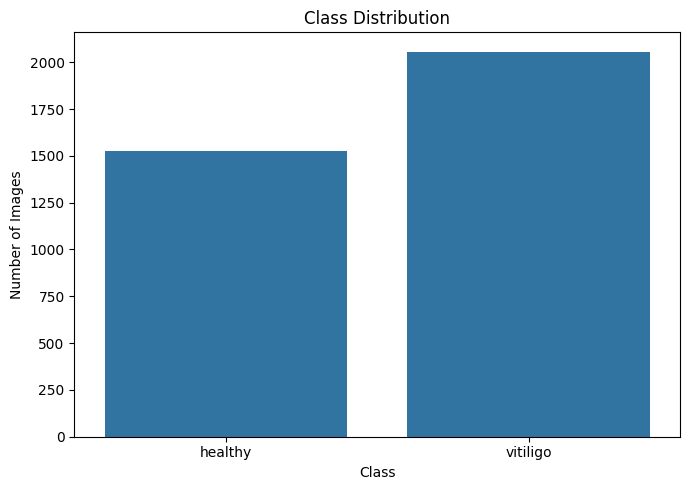


IMAGE QUALITY / DIMENSION CHECK

Corrupt/unreadable images: 0

Width statistics:
count    3585.000000
mean      698.370432
std       519.045934
min        80.000000
25%       416.000000
50%       416.000000
75%       612.000000
max      4100.000000
Name: width, dtype: float64

Height statistics:
count    3585.000000
mean      547.650488
std       385.408273
min        29.000000
25%       280.000000
50%       416.000000
75%       612.000000
max      2910.000000
Name: height, dtype: float64


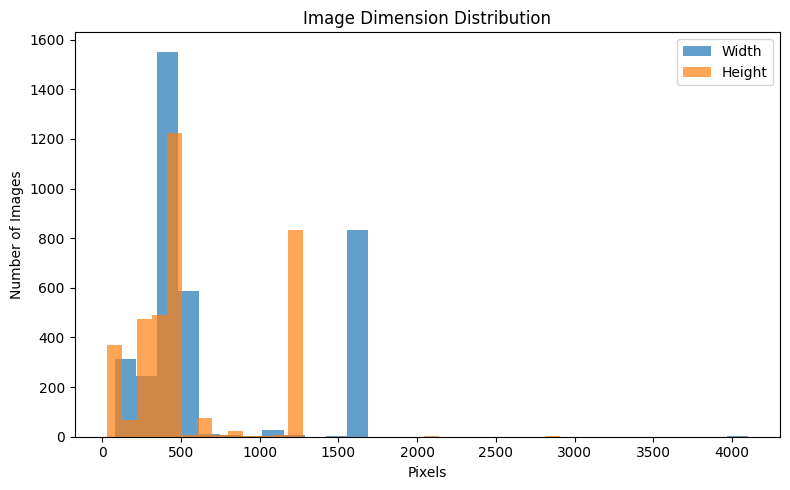


EXACT DUPLICATE CHECK
Duplicate groups: 3
Duplicate files beyond first copy: 3

Example duplicate groups:

Group:
  /kaggle/input/vitiligo/vitiligo/roi217_jpg.rf.ad699c848a5b28cbeee4c09a43f59099.jpg
  /kaggle/input/vitiligo/vitiligo/roi217_jpg.rf.957caa17c6aa32818f96cbcad98e6ef5.jpg

Group:
  /kaggle/input/vitiligo/vitiligo/roi226_jpg.rf.2a550bb5b0671077e9ca8e20c9632370.jpg
  /kaggle/input/vitiligo/vitiligo/roi226_jpg.rf.e646150ab56deee4f3d6b242b9701b97.jpg

Group:
  /kaggle/input/vitiligo/vitiligo/roi386.jpg
  /kaggle/input/vitiligo/vitiligo/roi384.jpg

Dataset size after removing exact duplicates: 3582

SAMPLE IMAGE VISUALIZATION


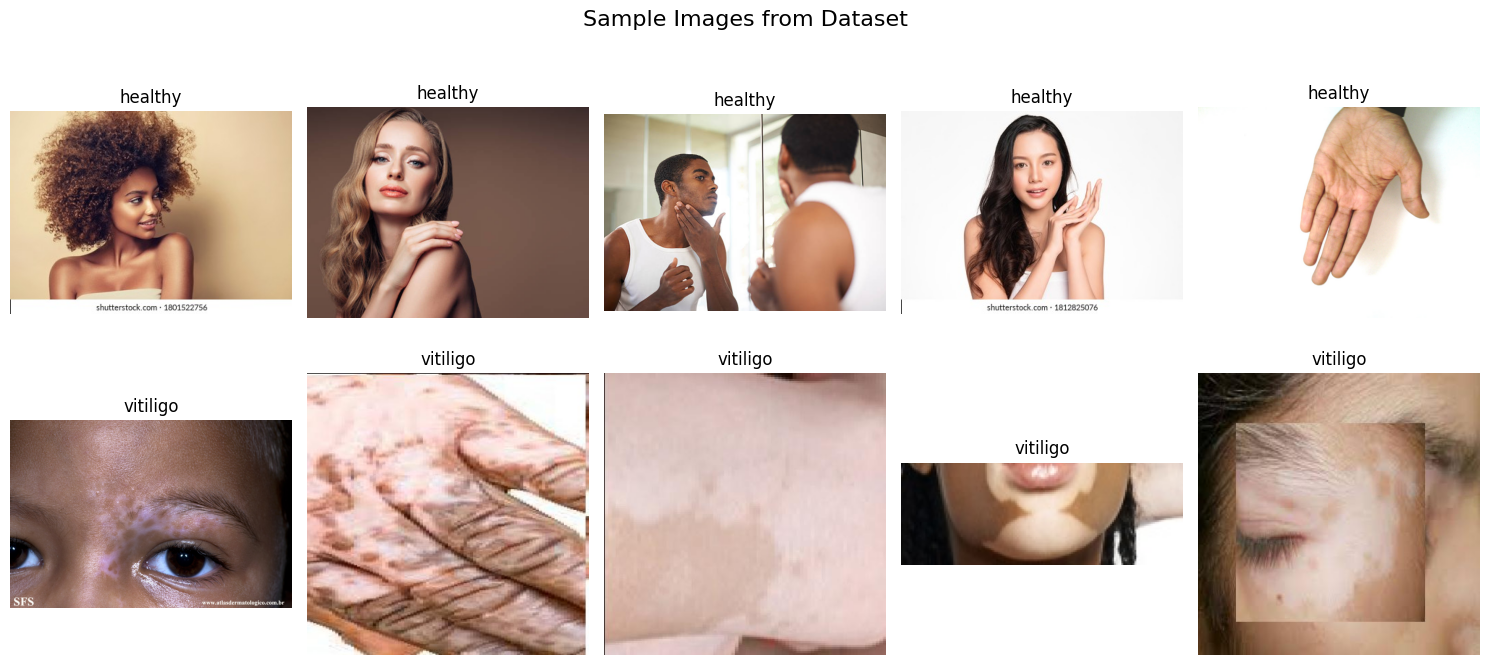


TRAIN / VALIDATION / TEST SPLIT
Train: 2507
Validation: 537
Test: 538

Train distribution:
class_name
vitiligo    1438
healthy     1069
Name: count, dtype: int64

Validation distribution:
class_name
vitiligo    308
healthy     229
Name: count, dtype: int64

Test distribution:
class_name
vitiligo    308
healthy     230
Name: count, dtype: int64

CREATING TENSORFLOW DATASETS

CREATING DATA AUGMENTATION

CALCULATING CLASS WEIGHTS
Class weights:
{0: 1.1725912067352666, 1: 0.8716968011126565}

BUILDING EFFICIENTNET-B0


Model: "VitiScan_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


INITIAL TRANSFER LEARNING
Epoch 1/15
78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.7033 - auc: 0.7695 - loss: 0.5455 - precision: 0.7510 - recall: 0.7344
Epoch 1: val_auc improved from None to 0.96543, saving model to /content/vitiscan_outputs/efficientnet_b0_best_initial.keras

Epoch 1: finished saving model to /content/vitiscan_outputs/efficientnet_b0_best_initial.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 181ms/step - accuracy: 0.8093 - auc: 0.9031 - loss: 0.4203 - precision: 0.8556 - recall: 0.8032 - val_accuracy: 0.8920 - val_auc: 0.9654 - val_loss: 0.2921 - val_precision: 0.9310 - val_recall: 0.8766 - learning_rate: 0.0010
Epoch 2/15
78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9044 - auc: 0.9667 - loss: 0.2766 - precision: 0.9358 - recall: 0.8951
Epoch 2: val_auc improved from 0.96543 to 0.97766, saving model to /content/vitiscan_outputs/efficientnet_b0_best_initial.keras

Epoch 2: finished saving model to /content/vitiscan_outputs/efficientnet_b0_best_initial.kera

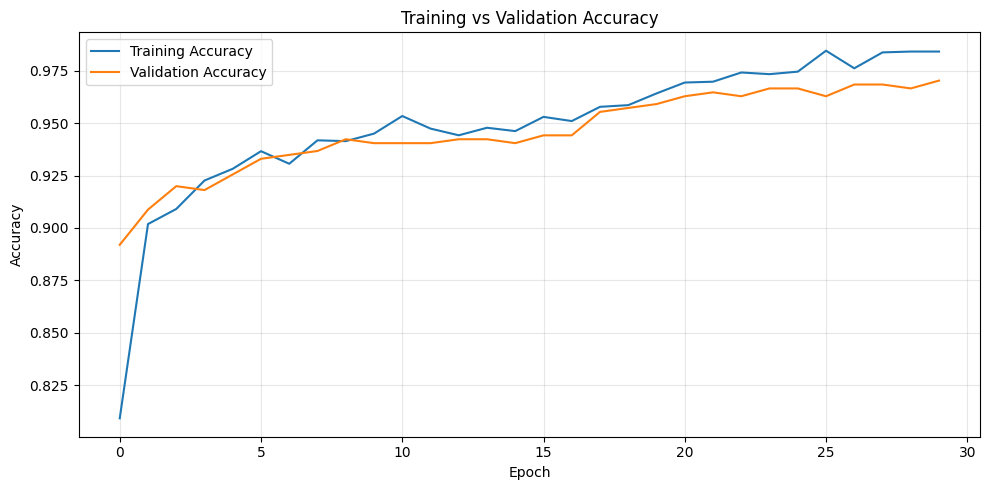

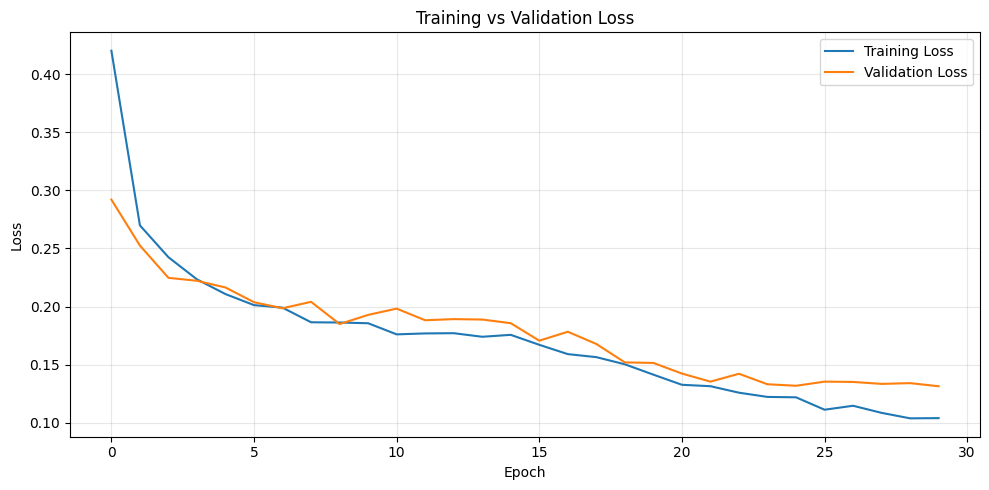

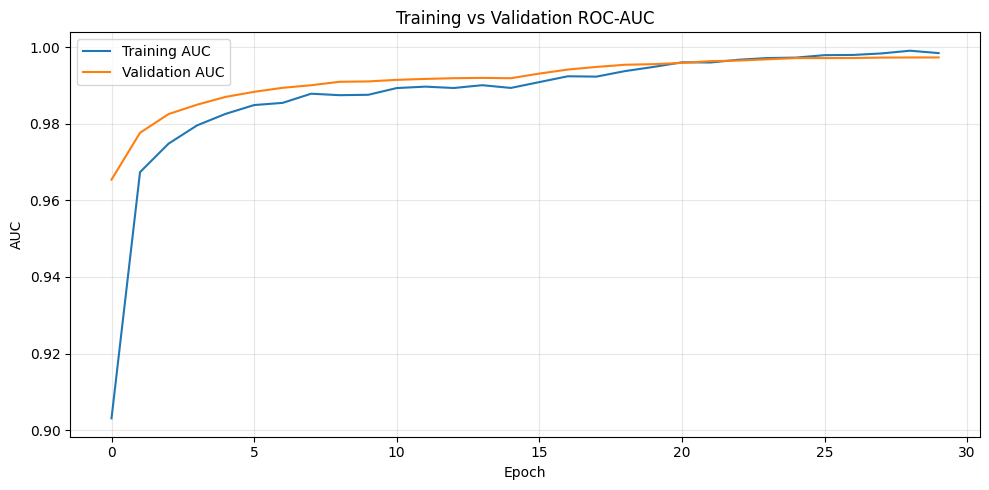


FINAL TEST EVALUATION
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step - accuracy: 0.9703 - auc: 0.9976 - loss: 0.1353 - precision: 0.9966 - recall: 0.9513
loss: 0.1353
compile_metrics: 0.9703

--------------------------------------------------
FINAL TEST METRICS
--------------------------------------------------
Accuracy : 0.9703
Precision: 0.9966
Recall   : 0.9513
F1 Score : 0.9734
ROC-AUC  : 0.9974

Classification Report:
              precision    recall  f1-score   support

     healthy     0.9385    0.9957    0.9662       230
    vitiligo     0.9966    0.9513    0.9734       308

    accuracy                         0.9703       538
   macro avg     0.9676    0.9735    0.9698       538
weighted avg     0.9718    0.9703    0.9704       538


CONFUSION MATRIX + ROC CURVE


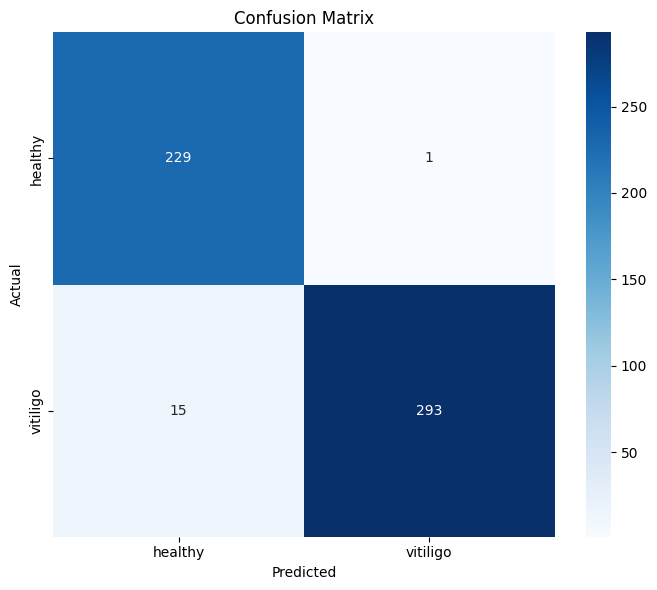

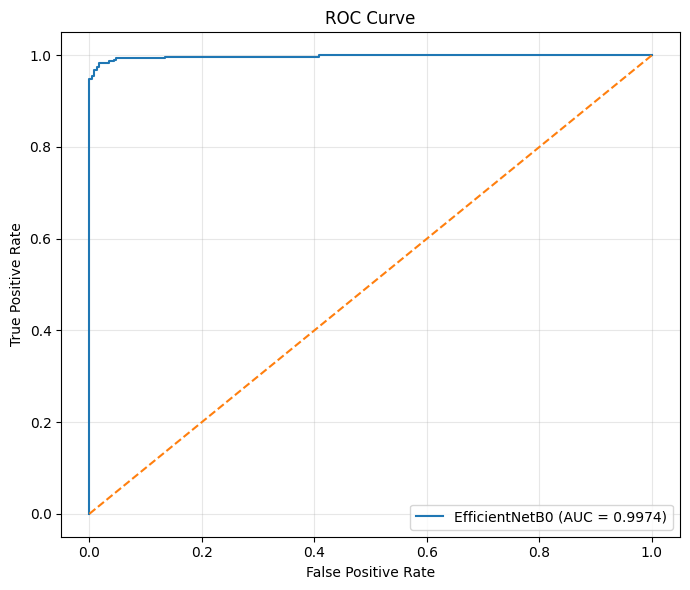


GRAD-CAM EXPLAINABILITY
Grad-CAM target layer: efficientnetb0

Final model saved to:
/content/vitiscan_outputs/VitiScan_EfficientNetB0_Final.keras

Results saved to:
/content/vitiscan_outputs/final_results.json

TRAINING PIPELINE COMPLETE

Saved files:
 - final_results.json
 - finetuning_log.csv
 - initial_training_log.csv
 - VitiScan_EfficientNetB0_Final.keras
 - efficientnet_b0_best_initial.keras
 - VitiScan_EfficientNetB0_best.keras

IMPORTANT:
This model is for research/educational classification.
It is NOT a medical diagnostic system.


In [4]:
# ============================================================
# 1. INSTALL / IMPORT LIBRARIES
# ============================================================

!pip -q install kagglehub

import os
import gc
import json
import random
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

warnings.filterwarnings("ignore")

print("=" * 70)
print("VITISCAN - FRESH TRAINING PIPELINE")
print("=" * 70)

# ============================================================
# 2. REPRODUCIBILITY + GPU CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\nTensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU detected:", gpus)

    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except:
            pass

    # Mixed precision for faster GPU training
    try:
        from tensorflow.keras import mixed_precision
        mixed_precision.set_global_policy("mixed_float16")
        print("Mixed precision: ENABLED")
    except Exception as e:
        print("Mixed precision could not be enabled:", e)

else:
    print("WARNING: No GPU detected.")
    print("Training will still work but will be much slower.")

# ============================================================
# 3. PROJECT CONFIGURATION
# ============================================================

DATASET_HANDLE = "shinynose/vitiligo"

IMAGE_SIZE = (224, 224)

BATCH_SIZE = 32

INITIAL_EPOCHS = 15
FINE_TUNE_EPOCHS = 15

INITIAL_LR = 1e-3
FINE_TUNE_LR = 1e-5

NUM_CLASSES = 2

CLASS_NAMES = ["healthy", "vitiligo"]

AUTOTUNE = tf.data.AUTOTUNE

OUTPUT_DIR = Path("/content/vitiscan_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nConfiguration")
print("-" * 70)
print("Dataset:", DATASET_HANDLE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Initial epochs:", INITIAL_EPOCHS)
print("Fine-tuning epochs:", FINE_TUNE_EPOCHS)
print("Output directory:", OUTPUT_DIR)

# ============================================================
# 4. DOWNLOAD KAGGLE DATASET
# ============================================================

print("\n" + "=" * 70)
print("DOWNLOADING KAGGLE DATASET")
print("=" * 70)

import kagglehub

dataset_path = kagglehub.dataset_download(DATASET_HANDLE)

print("\nDataset downloaded to:")
print(dataset_path)

# ============================================================
# 5. FIND HEALTHY + VITILIGO DIRECTORIES
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING DATASET STRUCTURE")
print("=" * 70)

dataset_path = Path(dataset_path)

all_dirs = [p for p in dataset_path.rglob("*") if p.is_dir()]

healthy_dirs = [
    p for p in all_dirs
    if p.name.lower() == "healthy"
]

vitiligo_dirs = [
    p for p in all_dirs
    if p.name.lower() == "vitiligo"
]

if not healthy_dirs or not vitiligo_dirs:
    print("\nDataset directory structure found:")
    for p in all_dirs[:50]:
        print(p)

    raise FileNotFoundError(
        "Could not automatically find 'healthy' and 'vitiligo' folders."
    )

HEALTHY_DIR = healthy_dirs[0]
VITILIGO_DIR = vitiligo_dirs[0]

print("Healthy folder :", HEALTHY_DIR)
print("Vitiligo folder:", VITILIGO_DIR)

# ============================================================
# 6. COLLECT ALL IMAGE PATHS
# ============================================================

print("\n" + "=" * 70)
print("COLLECTING IMAGES")
print("=" * 70)

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

def collect_images(folder, label):
    records = []

    for file in Path(folder).rglob("*"):
        if file.suffix.lower() in VALID_EXTENSIONS:
            records.append({
                "filepath": str(file),
                "label": label,
                "class_name": CLASS_NAMES[label]
            })

    return records


healthy_records = collect_images(HEALTHY_DIR, 0)
vitiligo_records = collect_images(VITILIGO_DIR, 1)

records = healthy_records + vitiligo_records

df = pd.DataFrame(records)

print("\nTotal images:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts())

if len(df) == 0:
    raise RuntimeError("No images were found.")

# ============================================================
# 7. BASIC DATASET EXPLORATION
# ============================================================

print("\n" + "=" * 70)
print("DATASET EXPLORATION")
print("=" * 70)

print("\nDataset shape:", df.shape)

print("\nClass counts:")
print(df["class_name"].value_counts())

print("\nClass percentages:")
print(
    (df["class_name"].value_counts(normalize=True) * 100)
    .round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="class_name"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

# ============================================================
# 8. IMAGE DIMENSION + CORRUPTION CHECK
# ============================================================

print("\n" + "=" * 70)
print("IMAGE QUALITY / DIMENSION CHECK")
print("=" * 70)

widths = []
heights = []
channels = []
corrupt_images = []

for path in df["filepath"]:

    try:

        with Image.open(path) as img:

            img.verify()

        with Image.open(path) as img:

            widths.append(img.width)
            heights.append(img.height)
            channels.append(len(img.getbands()))

    except Exception:

        corrupt_images.append(path)

print("\nCorrupt/unreadable images:", len(corrupt_images))

if corrupt_images:
    print("First few corrupt files:")
    for x in corrupt_images[:10]:
        print(x)

df["width"] = widths + [None] * (len(df) - len(widths))
df["height"] = heights + [None] * (len(df) - len(heights))

valid_dimension_df = df.dropna(subset=["width", "height"]).copy()

print("\nWidth statistics:")
print(valid_dimension_df["width"].describe())

print("\nHeight statistics:")
print(valid_dimension_df["height"].describe())

plt.figure(figsize=(8, 5))

plt.hist(
    valid_dimension_df["width"],
    bins=30,
    alpha=0.7,
    label="Width"
)

plt.hist(
    valid_dimension_df["height"],
    bins=30,
    alpha=0.7,
    label="Height"
)

plt.title("Image Dimension Distribution")
plt.xlabel("Pixels")
plt.ylabel("Number of Images")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 9. EXACT DUPLICATE CHECK
# ============================================================

print("\n" + "=" * 70)
print("EXACT DUPLICATE CHECK")
print("=" * 70)

def file_md5(path, chunk_size=1024 * 1024):

    md5 = hashlib.md5()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            md5.update(chunk)

    return md5.hexdigest()


hashes = []
hash_to_paths = {}

for i, path in enumerate(df["filepath"]):

    try:

        h = file_md5(path)

        hashes.append(h)

        hash_to_paths.setdefault(h, []).append(path)

    except:

        hashes.append(None)

df["md5"] = hashes

duplicate_groups = {
    h: paths
    for h, paths in hash_to_paths.items()
    if len(paths) > 1
}

duplicate_count = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

print("Duplicate groups:", len(duplicate_groups))
print("Duplicate files beyond first copy:", duplicate_count)

if duplicate_groups:

    print("\nExample duplicate groups:")

    for h, paths in list(duplicate_groups.items())[:5]:

        print("\nGroup:")

        for path in paths:
            print(" ", path)

# Keep only first copy of exact duplicates
if duplicate_groups:

    duplicate_hashes_to_remove = set()

    for h, paths in duplicate_groups.items():

        for duplicate_path in paths[1:]:
            duplicate_hashes_to_remove.add(duplicate_path)

    df = df[
        ~df["filepath"].isin(duplicate_hashes_to_remove)
    ].reset_index(drop=True)

    print(
        "\nDataset size after removing exact duplicates:",
        len(df)
    )

# ============================================================
# 10. SAMPLE IMAGE VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE IMAGE VISUALIZATION")
print("=" * 70)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(15, 7)
)

for class_index, class_name in enumerate(CLASS_NAMES):

    subset = df[
        df["class_name"] == class_name
    ].sample(
        min(5, len(df[df["class_name"] == class_name])),
        random_state=SEED
    )

    for col, (_, row) in enumerate(subset.iterrows()):

        image = Image.open(
            row["filepath"]
        ).convert("RGB")

        axes[class_index, col].imshow(image)
        axes[class_index, col].set_title(class_name)
        axes[class_index, col].axis("off")

plt.suptitle(
    "Sample Images from Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ============================================================
# 11. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

print("\n" + "=" * 70)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

# First: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

# Then: temporary → 15% validation + 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts())

print("\nTest distribution:")
print(test_df["class_name"].value_counts())

# ============================================================
# 12. CREATE TF.DATA DATASETS
# ============================================================

print("\n" + "=" * 70)
print("CREATING TENSORFLOW DATASETS")
print("=" * 70)

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.float32)

    return image, label


def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values
    labels = dataframe["label"].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:

        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        AUTOTUNE
    )

    return ds


train_ds = create_dataset(
    train_df,
    training=True
)

val_ds = create_dataset(
    val_df,
    training=False
)

test_ds = create_dataset(
    test_df,
    training=False
)

# ============================================================
# 13. DATA AUGMENTATION
# ============================================================

print("\n" + "=" * 70)
print("CREATING DATA AUGMENTATION")
print("=" * 70)

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal"
        ),

        layers.RandomRotation(
            0.04
        ),

        layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10
        ),

        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        ),
    ],
    name="data_augmentation"
)

# ============================================================
# 14. CLASS WEIGHTS
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING CLASS WEIGHTS")
print("=" * 70)

classes = np.unique(
    train_df["label"]
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)

# ============================================================
# 15. BUILD EFFICIENTNET-B0 MODEL
# ============================================================

print("\n" + "=" * 70)
print("BUILDING EFFICIENTNET-B0")
print("=" * 70)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMAGE_SIZE[0],
        IMAGE_SIZE[1],
        3
    )
)

# Initially freeze the pretrained backbone
base_model.trainable = False

inputs = keras.Input(
    shape=(
        IMAGE_SIZE[0],
        IMAGE_SIZE[1],
        3
    ),
    name="input_image"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

# Float32 output is important when mixed precision is enabled
outputs = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="prediction"
)(x)

model = keras.Model(
    inputs,
    outputs,
    name="VitiScan_EfficientNetB0"
)

model.summary()

# ============================================================
# 16. COMPILE + INITIAL TRANSFER LEARNING
# ============================================================

print("\n" + "=" * 70)
print("INITIAL TRANSFER LEARNING")
print("=" * 70)

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=INITIAL_LR
    ),

    loss=keras.losses.BinaryCrossentropy(
        label_smoothing=0.02
    ),

    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        ),

        keras.metrics.AUC(
            name="auc"
        )
    ]
)

checkpoint_initial = str(
    OUTPUT_DIR / "efficientnet_b0_best_initial.keras"
)

callbacks_initial = [

    ModelCheckpoint(
        checkpoint_initial,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    CSVLogger(
        str(
            OUTPUT_DIR /
            "initial_training_log.csv"
        )
    )
]

history_initial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_initial
)

# ============================================================
# 17. FINE-TUNING
# ============================================================

print("\n" + "=" * 70)
print("FINE-TUNING EFFICIENTNET-B0")
print("=" * 70)

base_model.trainable = True

# Freeze earlier layers and fine-tune only later layers
fine_tune_from = int(
    len(base_model.layers) * 0.70
)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    layer.trainable = True

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:

    if isinstance(
        layer,
        layers.BatchNormalization
    ):
        layer.trainable = False

trainable_count = sum(
    layer.trainable
    for layer in base_model.layers
)

print(
    "Trainable EfficientNet layers:",
    trainable_count
)

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LR
    ),

    loss=keras.losses.BinaryCrossentropy(
        label_smoothing=0.02
    ),

    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        keras.metrics.Precision(
            name="precision"
        ),

        keras.metrics.Recall(
            name="recall"
        ),

        keras.metrics.AUC(
            name="auc"
        )
    ]
)

checkpoint_finetuned = str(
    OUTPUT_DIR /
    "VitiScan_EfficientNetB0_best.keras"
)

callbacks_finetune = [

    ModelCheckpoint(
        checkpoint_finetuned,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    CSVLogger(
        str(
            OUTPUT_DIR /
            "finetuning_log.csv"
        ),
        append=True
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_finetune
)

# ============================================================
# 18. TRAINING CURVES
# ============================================================

print("\n" + "=" * 70)
print("TRAINING CURVES")
print("=" * 70)

def combine_history(h1, h2):

    history = {}

    keys = set(
        h1.history.keys()
    ).union(
        h2.history.keys()
    )

    for key in keys:

        history[key] = (
            h1.history.get(key, []) +
            h2.history.get(key, [])
        )

    return history


history = combine_history(
    history_initial,
    history_finetune
)

plt.figure(figsize=(10, 5))

plt.plot(
    history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    history["loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    history["auc"],
    label="Training AUC"
)

plt.plot(
    history["val_auc"],
    label="Validation AUC"
)

plt.title("Training vs Validation ROC-AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 19. FINAL TEST EVALUATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

# Load best saved model
if os.path.exists(checkpoint_finetuned):

    model = keras.models.load_model(
        checkpoint_finetuned
    )

test_results = model.evaluate(
    test_ds,
    verbose=1
)

for name, value in zip(
    model.metrics_names,
    test_results
):

    print(
        f"{name}: {value:.4f}"
    )

# Generate predictions
y_true = []
y_prob = []

for images, labels in test_ds:

    probabilities = model.predict(
        images,
        verbose=0
    ).ravel()

    y_prob.extend(
        probabilities
    )

    y_true.extend(
        labels.numpy()
    )

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

y_pred = (
    y_prob >= 0.5
).astype(int)

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

print("\n" + "-" * 50)
print("FINAL TEST METRICS")
print("-" * 50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 20. CONFUSION MATRIX + ROC CURVE
# ============================================================

print("\n" + "=" * 70)
print("CONFUSION MATRIX + ROC CURVE")
print("=" * 70)

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"EfficientNetB0 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 21. GRAD-CAM + MODEL SAVING + SINGLE IMAGE PREDICTION
# ============================================================

print("\n" + "=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# ------------------------------------------------------------
# Find the final convolutional layer automatically
# ------------------------------------------------------------

def find_last_conv_layer(model):

    for layer in reversed(model.layers):

        try:

            output_shape = layer.output.shape

            if len(output_shape) == 4:

                return layer.name

        except:

            continue

    raise ValueError(
        "Could not find a convolutional layer."
    )


LAST_CONV_LAYER = find_last_conv_layer(
    model
)

print(
    "Grad-CAM target layer:",
    LAST_CONV_LAYER
)

# ------------------------------------------------------------
# Grad-CAM function
# ------------------------------------------------------------

def make_gradcam_heatmap(
    image_array,
    model,
    last_conv_layer_name
):

    grad_model = tf.keras.models.Model(
        [
            model.inputs
        ],
        [
            model.get_layer(
                last_conv_layer_name
            ).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_array
        )

        class_channel = predictions[:, 0]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = heatmap / (
        max_value + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()


# ------------------------------------------------------------
# SAVE FINAL MODEL
# ------------------------------------------------------------

final_model_path = (
    OUTPUT_DIR /
    "VitiScan_EfficientNetB0_Final.keras"
)

model.save(
    final_model_path
)

print("\nFinal model saved to:")
print(final_model_path)


# ------------------------------------------------------------
# SAVE TEST RESULTS
# ------------------------------------------------------------

results = {
    "model": "EfficientNetB0",
    "dataset": DATASET_HANDLE,
    "total_images": int(len(df)),
    "train_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "test_images": int(len(test_df)),
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc)
}

results_path = (
    OUTPUT_DIR /
    "final_results.json"
)

with open(
    results_path,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print("\nResults saved to:")
print(results_path)


# ------------------------------------------------------------
# SINGLE IMAGE PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_single_image(
    image_path,
    model=model
):

    image = Image.open(
        image_path
    ).convert("RGB")

    image = image.resize(
        IMAGE_SIZE
    )

    image_array = np.array(
        image
    ).astype("float32")

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    probability = float(
        model.predict(
            image_array,
            verbose=0
        )[0][0]
    )

    predicted_class = (
        "vitiligo"
        if probability >= 0.5
        else "healthy"
    )

    confidence = (
        probability
        if predicted_class == "vitiligo"
        else 1 - probability
    )

    print("\nPrediction")
    print("-" * 40)
    print("Class:", predicted_class)
    print(
        f"Confidence: {confidence * 100:.2f}%"
    )
    print(
        f"Vitiligo probability: {probability * 100:.2f}%"
    )

    return predicted_class, confidence


print("\n" + "=" * 70)
print("TRAINING PIPELINE COMPLETE")
print("=" * 70)

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(" -", file.name)

print("\nIMPORTANT:")
print("This model is for research/educational classification.")
print("It is NOT a medical diagnostic system.")

FIXED GRAD-CAM EXPLAINABILITY
Base model: efficientnetb0
Grad-CAM target layer: top_conv
Target layer output shape: (None, 7, 7, 1280)

Grad-CAM examples:
----------------------------------------------------------------------


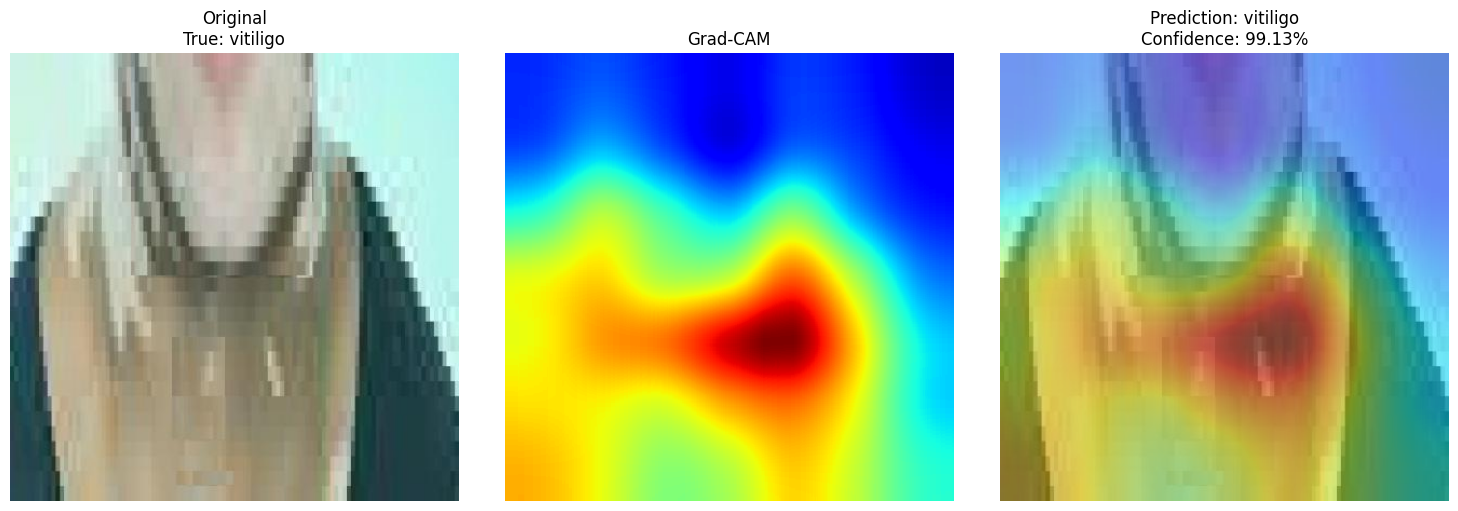

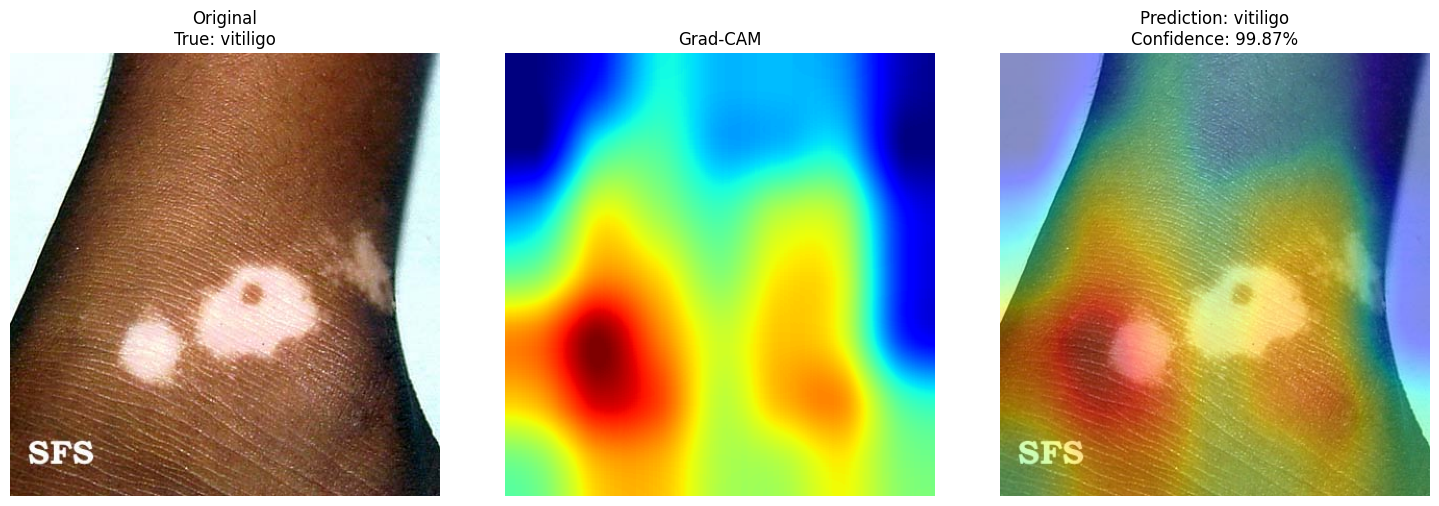

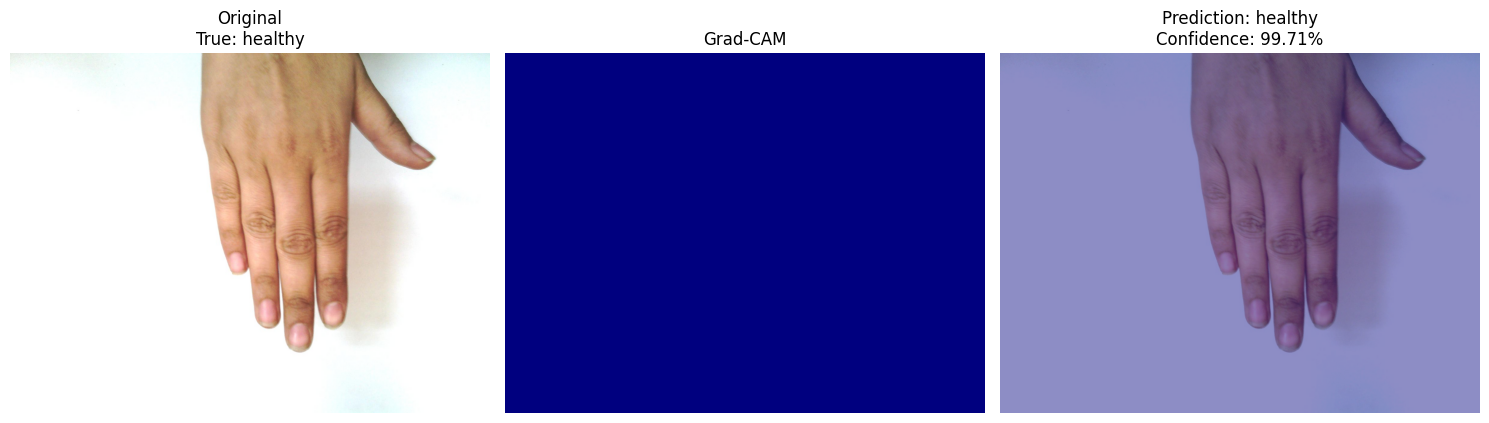

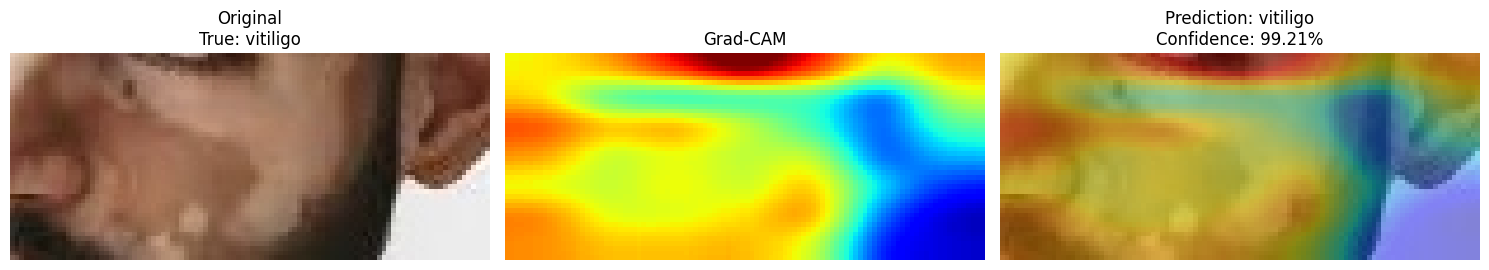

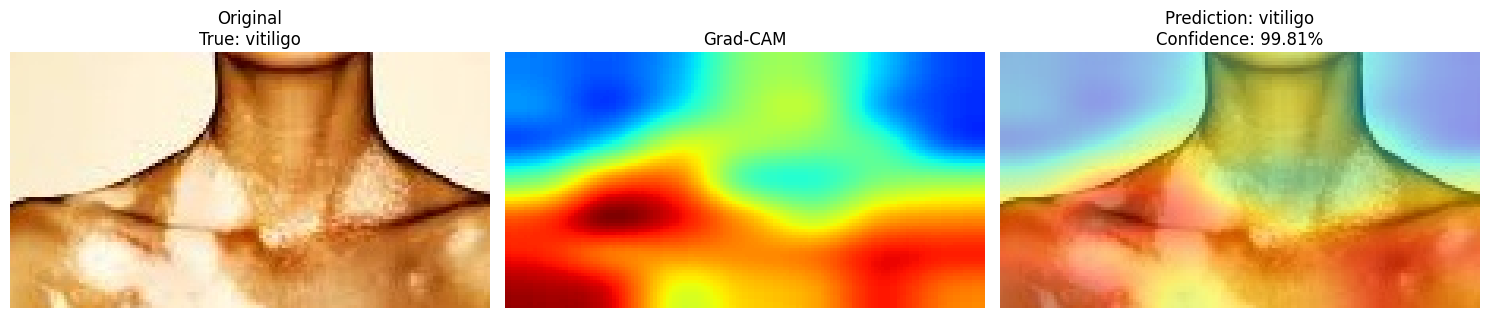


GRAD-CAM COMPLETED SUCCESSFULLY


In [5]:
# ============================================================
# FIXED GRAD-CAM FOR VITISCAN EFFICIENTNET-B0
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("FIXED GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get the trained EfficientNet model
# ------------------------------------------------------------

base_model = model.get_layer("efficientnetb0")

# IMPORTANT:
# Grad-CAM must use an internal convolutional feature layer,
# NOT the complete nested EfficientNet model.
target_layer = base_model.get_layer("top_conv")

print("Base model:", base_model.name)
print("Grad-CAM target layer:", target_layer.name)
print("Target layer output shape:", target_layer.output.shape)


# ------------------------------------------------------------
# 2. Build a separate Grad-CAM model
# ------------------------------------------------------------

grad_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        target_layer.output,
        base_model.output
    ],
    name="VitiScan_GradCAM_Model"
)

gap_layer = model.get_layer("global_average_pooling")
prediction_layer = model.get_layer("prediction")


# ------------------------------------------------------------
# 3. Grad-CAM heatmap function
# ------------------------------------------------------------

def make_gradcam_heatmap(image_array):

    # Apply the SAME augmentation pipeline as the trained model,
    # but keep training=False so there is no random augmentation.
    augmented_image = model.get_layer("data_augmentation")(
        image_array,
        training=False
    )

    with tf.GradientTape() as tape:

        # Get convolutional feature maps + EfficientNet output
        conv_outputs, base_output = grad_model(
            augmented_image,
            training=False
        )

        # Same layers used by the original model
        pooled_output = gap_layer(base_output)
        predictions = prediction_layer(pooled_output)

        # Binary classification: vitiligo probability
        vitiligo_score = predictions[:, 0]

    # Gradient of vitiligo score w.r.t. feature maps
    grads = tape.gradient(
        vitiligo_score,
        conv_outputs
    )

    # Average gradients over height and width
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(heatmap, 0)

    # Normalize
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy()


# ------------------------------------------------------------
# 4. Display Grad-CAM
# ------------------------------------------------------------

def display_gradcam(image_path, model, true_class):

    # Load original image
    original_image = Image.open(image_path).convert("RGB")

    # Keep original image for visualization
    original_array = np.array(original_image)

    # Resize to model input size
    image_resized = original_image.resize((224, 224))

    image_array = np.array(
        image_resized,
        dtype=np.float32
    )

    # Add batch dimension
    batch = np.expand_dims(
        image_array,
        axis=0
    )

    # Generate Grad-CAM
    heatmap = make_gradcam_heatmap(batch)

    # Resize heatmap to original image size
    heatmap_resized = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(
        original_image.size
    )

    heatmap_resized = np.array(
        heatmap_resized
    ) / 255.0

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    prediction = model.predict(
        batch,
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = "vitiligo"
        confidence = prediction
    else:
        predicted_class = "healthy"
        confidence = 1 - prediction

    # --------------------------------------------------------
    # Create colored heatmap
    # --------------------------------------------------------

    colored_heatmap = plt.get_cmap("jet")(
        heatmap_resized
    )[:, :, :3]

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(original_array)
    plt.axis("off")
    plt.title(
        f"Original\nTrue: {true_class}"
    )

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(colored_heatmap)
    plt.axis("off")
    plt.title("Grad-CAM")

    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(original_array)
    plt.imshow(
        colored_heatmap,
        alpha=0.45
    )
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. Run Grad-CAM on test samples
# ============================================================

print("\nGrad-CAM examples:")
print("-" * 70)

sample_test = test_df.sample(
    n=min(5, len(test_df)),
    random_state=42
)

for _, row in sample_test.iterrows():

    display_gradcam(
        row["filepath"],
        model,
        row["class_name"]
    )

print("\n" + "=" * 70)
print("GRAD-CAM COMPLETED SUCCESSFULLY")
print("=" * 70)